## Expected signature of a 3-dimensional time-extended OU process with compound Poisson jumps

## Goal

We compute the **expected signature** (truncated at level $N$) at time $T>0$ of the process $\widehat{X}$ described below by means of the polynomial formula, that reads



$$\mathbb{E}\big[\mathbb{X}_T^{\leq N}\big]=
 \exp(TL^\top)\,\mathbb{X}_0^{\leq N} = \exp(TL^\top)\,\epsilon_\varnothing$$

since the signature at time $0$ is the empty-word unit, $\mathbb{X}_0^{\leq N} = \epsilon_\varnothing$.  



The whole computation therefore reduces to **assembling $L$**, the matrix representing the action of the generator on $\{e_I, |I|\leq N\}$, the flat basis of words of length $0, \dots, N$ over the alphabet $\{1, \dots, d\}$. Its construction is the subject of `construction_matrix_demo.ipynb`: writing $I^{(k)}$ for the word $I$ with its last $k$ letters removed ($I' := I^{(1)}$, $I'' := I^{(2)}$) and $\#$ for the shuffle product,

$$
L e_I = e_{I'} \# \mathbf{b}^{i_{|I|}}
      + \frac{1}{2} e_{I''} \# (\mathbf{a} + \mathbf{k}^2)^{i_{|I|-1}, i_{|I|}}
      + \sum_{k=3}^{|I|} \frac{1}{k!} e_{I^{(k)}} \# (\mathbf{k}^k)^{i_{|I|-k+1}, \dots, i_{|I|}},
$$

with $|I|$ the length of the multiindex $I$.

The only model-dependent input is the table of partial derivatives, evaluated at $\widehat{X}_0$, of the components of the tensors $Q^{(1)}, \dots, Q^{(\text{max rank})}$.

This notebook carries that programme out for one concrete example: a **time-extended 2-dimensional Ornstein–Uhlenbeck process with compound Poisson jumps**, $$\widehat{X}_t = (t, X^{(1)}_t, X^{(2)}_t),$$ whose two OU coordinates are driven by independent Brownian motions but **jump simultaneously**.

**Outline.** After specifying the model and its characteristics, we 

1. fill the partial-derivatives table,
2. pack it into the flat tensor basis, 
3. assemble $L$ and exponentiate it to obtain the expected signature,
4. compare the results against a  Monte Carlo simulation.

---




## The model

We consider a 3-dimensional process $\widehat{X}_t = (t, X^{(1)}_t, X^{(2)}_t)$, where the last two coordinates follow independent Ornstein-Uhlenbeck dynamics with compound Poisson jumps.

The dynamics are:
$$\mathrm{d}X^{(i)}_t = (\alpha_i + \beta_i X^{(i)}_{t-})\,\mathrm{d}t + \sigma_i\,\mathrm{d}W^{(i)}_t + \mathrm{d}J^{(i)}_t,\qquad i = 1,2,\qquad X_0=(c_1,c_2)\in \mathbb{R}^2,$$

with $W^{(i)}$ independent 1-dimensional Brownian motions and jumps $J^{(i)}_t = \sum_{k=1}^{N_t} Z^{(i)}_k$ and $N_t \sim \mathrm{Poisson}(\lambda t)$. The jump sizes $Z_k = (Z^{(1)}_k, Z^{(2)}_k)$ are drawn from the 2-dimensional Gaussian distribution $F = \mathcal{N}(\mu, \Sigma)$ with mean $\mu = (\mu_1, \mu_2)$ and covariance matrix $\Sigma = \mathrm{diag}(\Sigma_{11}, \Sigma_{22})$.


### Characteristic coefficients

The coefficients of the characteristics of $\widehat{X}$ are given by
$$b(x_1,x_2,x_3) = \begin{pmatrix} 1 \\ \alpha_1 + \beta_1 x_2 + \lambda \mu_1 \\ \alpha_2 + \beta_2 x_3 + \lambda \mu_2 \end{pmatrix}, \qquad a(x_1,x_2,x_3) = \begin{pmatrix} 0 & 0 & 0 \\ 0 & \sigma_1^2 & 0 \\ 0 & 0 & \sigma_2^2 \end{pmatrix},$$

with a state-independent jump kernel that only affects the OU coordinates:
$$K(x_1,x_2,x_3, d\xi) = \lambda\, j(\xi_1, \xi_2,\xi_3)_* F(d\xi), \qquad j(\xi_1, \xi_2,\xi_3) = (0, \xi_2, \xi_3).$$




### Tensors $Q^{(r)}(\boldsymbol {x})$, for $r\geq 1$.

The tensors $Q^{(r)}(\boldsymbol{x})$, for $\boldsymbol{x}\in \mathcal{S}$, read as follows:
$$Q^{(1)}(\boldsymbol{x}) = \begin{pmatrix} 1 \\ \alpha_1 + \beta_1 \langle \epsilon_2, \boldsymbol{x}\rangle  + \lambda \mu_1  + \beta_1 c_1 \\ \alpha_2 + \beta_2 \langle \epsilon_3, \boldsymbol{x}\rangle  + \lambda \mu_2 + \beta_2 c_2 \end{pmatrix},$$

$$Q^{(2)}(\boldsymbol{x}) = \begin{pmatrix} 0 & 0 & 0 \\ 0 & \sigma_1^2 + \lambda (\mu_1^2 + \Sigma_{11}) & \lambda \mu_1 \mu_2 \\ 0 & \lambda \mu_1 \mu_2 & \sigma_2^2 + \lambda (\mu_2^2 + \Sigma_{22}) \end{pmatrix},$$

$$Q^{(r)}(\boldsymbol{x}) = \lambda \mathbb{E}_F[\xi^{\otimes r}], \qquad r \ge 3,$$

Notice that $$\alpha_1 + \lambda \mu_1  + \beta_1 c_1 = b_2(\widehat{X}_0), \qquad  \beta_1  =\partial_2b_2(\widehat{X}_0),$$
$$\alpha_2 + \lambda \mu_2  + \beta_2 c_2 = b_3(\widehat{X}_0), \qquad \beta_2  =\partial_3b_3(\widehat{X}_0),$$


In [1]:
%load_ext autotime
import sys
if ".." not in sys.path:
    sys.path.insert(0, "..")

from typing import Sequence

import numpy as np
import pandas as pd
import iisignature
import itertools

from poly_jump_signature import (
    create_storage_df, derivatives_to_tensor_df, matrix_generator,
    expected_signature, fromlentonum, fromwordtonum, fromnumtoword, 
)

time: 360 ms (started: 2026-11-26 11:27:44 +01:00)


## 1. Partial derivatives table

`create_storage_df(max_rank, d)` builds a placeholder table — **every coefficient set to `1.0`** — for the partial derivatives, evaluated at $\widehat{X}_0$, of the components of $Q^{(1)}, \dots, Q^{(5)}$. The table is indexed by (`Tensor_rank`, `Component_tensor_Q^rank`, `Order_derivative`, `Derivative_multiindex`). 

Since for this specific model we get,

| tensor | $x$-dependence | orders of partial derivatives needed |
|---|---|---|
| $Q^{(1)} $ | affine | 0 and 1 |
| $Q^{(2)}$ | constant | 0 only |
| $Q^{(3)} $ | constant | 0 only |
| $Q^{(4)} $ | constant | 0 only |
| $Q^{(5)} $ | constant | 0 only |

we fill the table in code below rather than via the CSV round-trip (`to_csv` → edit by hand → `load_storage_from_template_df`). 

Observe that the non-null jump moments of order $3$ for the 2-dimensional normal law appearing in $Q^{(3)}$ are:
$$\mathbb{E}_F[\xi_1^3] = \mu_1^3 + 3 \mu_1 \Sigma_{11}, \qquad \mathbb{E}_F[\xi_2^3] = \mu_2^3 + 3 \mu_2 \Sigma_{22},$$
$$\mathbb{E}_F[\xi_1^2 \xi_2] = \mu_2 (\mu_1^2 + \Sigma_{11}), \qquad \mathbb{E}_F[\xi_1 \xi_2^2] = \mu_1 (\mu_2^2 + \Sigma_{22}).$$

Similarly, the jump moments of order $4$ appearing in $Q^{(4)}$ are:
$$\mathbb{E}_F[\xi_1^4] = \mu_1^4 + 6 \mu_1^2 \Sigma_{11} + 3 \Sigma_{11}^2, \qquad \mathbb{E}_F[\xi_2^4] = \mu_2^4 + 6 \mu_2^2 \Sigma_{22} + 3 \Sigma_{22}^2,$$
$$\mathbb{E}_F[\xi_1^3 \xi_2] = \mu_2 (\mu_1^3 + 3 \mu_1 \Sigma_{11}), \qquad \mathbb{E}_F[\xi_1 \xi_2^3] = \mu_1 (\mu_2^3 + 3 \mu_2 \Sigma_{22}),$$
$$\mathbb{E}_F[\xi_1^2 \xi_2^2] = (\mu_1^2 + \Sigma_{11})(\mu_2^2 + \Sigma_{22}).$$

Finally, the jump moments of order $5$ appearing in $Q^{(5)}$ are:
$$\mathbb{E}_F[\xi_1^5] = \mu_1^5 + 10 \mu_1^3 \Sigma_{11} + 15 \mu_1 \Sigma_{11}^2, \qquad \mathbb{E}_F[\xi_2^5] = \mu_2^5 + 10 \mu_2^3 \Sigma_{22} + 15 \mu_2 \Sigma_{22}^2,$$
$$\mathbb{E}_F[\xi_1^4 \xi_2] = \mu_2 (\mu_1^4 + 6 \mu_1^2 \Sigma_{11} + 3 \Sigma_{11}^2), \qquad \mathbb{E}_F[\xi_1 \xi_2^4] = \mu_1 (\mu_2^4 + 6 \mu_2^2 \Sigma_{22} + 3 \Sigma_{22}^2),$$
$$\mathbb{E}_F[\xi_1^3 \xi_2^2] = (\mu_2^2 + \Sigma_{22})(\mu_1^3 + 3 \mu_1 \Sigma_{11}), \qquad \mathbb{E}_F[\xi_1^2 \xi_2^3] = (\mu_1^2 + \Sigma_{11})(\mu_2^3 + 3 \mu_2 \Sigma_{22}).$$


In [2]:
d = 3
max_rank = 3

# --- 3D time-extended OU + Gaussian compound Poisson parameters ------------
alpha1, alpha2 = 0.25, 0.10       # OU drift constants
beta1, beta2 = -0.7, -0.5         # mean-reversion speeds
sigma1, sigma2 = 0.6, 0.5         # diffusion coefficients
lam = 1.3                         # jump intensity
mu1, mu2 = 1.2, -0.8              # jump-size means
Sigma11, Sigma22 = 0.5, 0.4       # jump-size variances

# Initial point of the OU coordinates. The time coordinate always starts at 0.
c1, c2 = 0.4, -0.3
X0 = np.array([0.0, c1, c2])      # all derivatives are evaluated here

# --- jump moments of F = N(mu, diag(Sigma11, Sigma22)) ---------------------
m2_11 = mu1**2 + Sigma11                  # E[xi_1^2]
m2_22 = mu2**2 + Sigma22                  # E[xi_2^2]
m2_12 = mu1 * mu2                         # E[xi_1 xi_2]
m3_111 = mu1**3 + 3 * mu1 * Sigma11       # E[xi_1^3]
m3_222 = mu2**3 + 3 * mu2 * Sigma22       # E[xi_2^3]
m3_112 = mu2 * m2_11                      # E[xi_1^2 xi_2]
m3_122 = mu1 * m2_22                      # E[xi_1 xi_2^2]

m4_1111 = mu1**4 + 6 * mu1**2 * Sigma11 + 3 * Sigma11**2   # E[xi_1^4]
m4_2222 = mu2**4 + 6 * mu2**2 * Sigma22 + 3 * Sigma22**2   # E[xi_2^4]
m4_1112 = mu2 * m3_111                                     # E[xi_1^3 xi_2]
m4_1222 = mu1 * m3_222                                     # E[xi_1 xi_2^3]
m4_1122 = m2_11 * m2_22                                    # E[xi_1^2 xi_2^2]

m5_11111 = mu1**5 + 10 * mu1**3 * Sigma11 + 15 * mu1 * Sigma11**2   # E[xi_1^5]
m5_22222 = mu2**5 + 10 * mu2**3 * Sigma22 + 15 * mu2 * Sigma22**2   # E[xi_2^5]
m5_11112 = mu2 * m4_1111                                            # E[xi_1^4 xi_2]
m5_12222 = mu1 * m4_2222                                            # E[xi_1 xi_2^4]
m5_11122 = m3_111 * m2_22                                           # E[xi_1^3 xi_2^2]
m5_11222 = m2_11 * m3_222                                           # E[xi_1^2 xi_2^3]

# Constant part of the drift, b^i = k_i + beta_i x_{i+1}.
k1 = alpha1 + lam * mu1
k2 = alpha2 + lam * mu2

storage = create_storage_df(max_rank, d)

# create_storage_df fills EVERY coefficient with the placeholder 1.0,
# so the table must be zeroed before the model's actual values are written.
storage['Value'] = 0.0



def set_coef(value: float,
             rank: int,
             component: Sequence[int],
             multiindex: Sequence[int] = ()) -> None:
    """Store one generator coefficient: the partial derivative of the
    `component` entry of Q^(rank), taken along `multiindex` and evaluated
    at X0.


    Parameters
    ----------
    value : float
        Value of the derivative at X0.
    rank : int
        Rank r of the tensor Q^(r), in {1, ..., max_rank}.
    component : Sequence[int], length rank
        Component of Q^(rank), entries in {1, ..., d}.
    multiindex : Sequence[int], length <= rank, optional
        Derivative multi-index, entries in {1, ..., d}.  Empty (the default)
        means the value of the component itself.

    Returns
    -------
    None
        `storage` is modified in place.

    Raises
    ------
    KeyError
        If no row matches the (rank, component, multiindex) triple.
    """
    component, multiindex = tuple(sorted(component)), tuple(sorted(multiindex))
    mask = ((storage['Tensor_rank'] == rank)
            & (storage['Component_tensor_Q^rank'] == component)
            & (storage['Derivative_multiindex'] == multiindex))

    storage.loc[mask, 'Value'] = value


# --- Q^(1) = b(x): the only x-dependent tensor, affine in x ---------------
set_coef(1.0, rank=1, component=(1,))                     # time
set_coef(k1 + beta1 * c1, rank=1, component=(2,))         # b^2(X_0)
set_coef(k2 + beta2 * c2, rank=1, component=(3,))         # b^3(X_0)
set_coef(beta1, rank=1, component=(2,), multiindex=(2,))   # d b^2 / d x_2
set_coef(beta2, rank=1, component=(3,), multiindex=(3,))   # d b^3 / d x_3

# --- Q^(2) -----------------------
q2_22 = sigma1**2 + lam * m2_11
q2_33 = sigma2**2 + lam * m2_22
q2_23 = lam * m2_12                 
set_coef(q2_22, rank=2, component=(2, 2))
set_coef(q2_33, rank=2, component=(3, 3))
set_coef(q2_23, rank=2, component=(2, 3))

# --- Q^(3) ---------------------------
set_coef(lam * m3_111, rank=3, component=(2, 2, 2))
set_coef(lam * m3_112, rank=3, component=(2, 2, 3))
set_coef(lam * m3_122, rank=3, component=(2, 3, 3))
set_coef(lam * m3_222, rank=3, component=(3, 3, 3))

# --- Q^(4) ---------------------------
set_coef(lam * m4_1111, rank=4, component=(2, 2, 2, 2))
set_coef(lam * m4_1112, rank=4, component=(2, 2, 2, 3))
set_coef(lam * m4_1122, rank=4, component=(2, 2, 3, 3))
set_coef(lam * m4_1222, rank=4, component=(2, 3, 3, 3))
set_coef(lam * m4_2222, rank=4, component=(3, 3, 3, 3))

# --- Q^(5) ---------------------------
set_coef(lam * m5_11111, rank=5, component=(2, 2, 2, 2, 2))
set_coef(lam * m5_11112, rank=5, component=(2, 2, 2, 2, 3))
set_coef(lam * m5_11122, rank=5, component=(2, 2, 2, 3, 3))
set_coef(lam * m5_11222, rank=5, component=(2, 2, 3, 3, 3))
set_coef(lam * m5_12222, rank=5, component=(2, 3, 3, 3, 3))
set_coef(lam * m5_22222, rank=5, component=(3, 3, 3, 3, 3))

# Components involving index 1 stay at zero for rank >= 2

storage[storage['Value'] != 0]

,Tensor_rank,Component_tensor_Q^rank,Order_derivative,Derivative_multiindex,Value
0,1,"(1,)",0,(),1.0000
4,1,"(2,)",0,(),1.5300
6,1,"(2,)",1,"(2,)",-0.7000
8,1,"(3,)",0,(),-0.7900
11,1,"(3,)",1,"(3,)",-0.5000
42,2,"(2, 2)",0,(),2.8820
52,2,"(2, 3)",0,(),-1.2480
62,2,"(3, 3)",0,(),1.6020
192,3,"(2, 2, 2)",0,(),4.5864
212,3,"(2, 2, 3)",0,(),-2.0176


time: 10.6 ms (started: 2026-11-26 11:27:44 +01:00)


## 2. Tensor-basis packing

In [3]:
df = derivatives_to_tensor_df(storage, d)
df

,Tensor_rank,Component_tensor_Q^rank,Vector_tensor_num
0,1,"(1,)","[1.0, 0.0, 0.0, 0.0]"
1,1,"(2,)","[1.53, 0.0, -0.7, 0.0]"
2,1,"(3,)","[-0.79, 0.0, 0.0, -0.5]"
3,2,"(1, 1)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,2,"(1, 2)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
5,2,"(1, 3)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
6,2,"(2, 2)","[2.8819999999999997, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
7,2,"(2, 3)","[-1.248, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0...."
8,2,"(3, 3)","[1.602, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0..."
9,3,"(1, 1, 1)","[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


time: 9.48 ms (started: 2026-11-26 11:27:45 +01:00)


## 3. Generator matrix and expected signature 

In [4]:
len_max = max_rank
L = matrix_generator(storage, len_max, d)
print('L shape:', L.shape)
L

T = 1.0
Es = expected_signature(storage, len_max, d, T)
Es

L shape: (40, 40)


array([ 1.        ,  1.        ,  1.10032069, -0.62168156,  0.5       ,
        0.48649311, -0.28504467,  0.61382758,  1.3808198 , -0.76010249,
       -0.33663688, -0.65070461,  0.69957255,  0.16666667,  0.15229336,
       -0.09093012,  0.18190638,  0.67394396, -0.34357301, -0.10318442,
       -0.30657244,  0.36162493,  0.2159606 , -0.00693588, -0.04873619,
        0.71381172,  1.39471564, -0.81435801, -0.36779329, -0.5981978 ,
        0.6713374 , -0.11672623, -0.01428286, -0.02942298, -0.32984931,
       -0.69707558,  0.40195934,  0.36737059,  0.53827366, -0.52000033])

time: 32.9 ms (started: 2026-11-26 11:27:45 +01:00)


## 4. Monte Carlo simulation comparison




In this section we check the polynomial formula for $\mathbb{E}\big[\mathbb{X}_T^{\leq N}\big]$ against a direct Monte Carlo simulation.

We simulate $M$ independent paths of the process on $[0,T]$ and compute, for each path, the truncated signature up to level $N$. For every word $I$ with $|I| \leq N$, we estimate $\mathbb{E}[\mathbb{X}_T^I]$ by the sample mean $\bar X_I$, together with its standard error $SE_I$.

For each word $I$, we then compare the exact value $\mathbb{E}[\mathbb{X}_T^I]$ computed via the polynomial formula with the Monte Carlo estimate $\bar X_I$. The formula is validated on word $I$ if the exact value lies in $\bar X_I \pm 2\,SE_I$, an approximate confidence interval of level 95%.


### Path simulation and signature computation via piecewise linear interpolation

The signature of $\widehat{X}$ can be computed with any standard signature package, which treats the path as piecewise linear between the sampled points. This is the approach we adopt here. We first simulate the paths, and then compute their signatures.

In [5]:
# --- pack the scalar parameters defined in Section 1 into vectors for the
# two OU coordinates, as needed by `simulate` below --------------------
c = np.array([c1, c2])
alpha = np.array([alpha1, alpha2])
beta = np.array([beta1, beta2])
sig = np.array([sigma1, sigma2])
mu = np.array([mu1, mu2])
Sig = np.array([Sigma11, Sigma22])


time: 175 μs (started: 2026-11-26 11:27:45 +01:00)


In [6]:
def simulate(n_paths, n_steps, seed=0):
    np.random.seed(seed)
    dt = T / n_steps

    X = np.empty((n_paths, n_steps + 1, 3))
    X[:, :, 0] = np.linspace(0.0, T, n_steps + 1)  # time channel

    Y = np.tile(c, (n_paths, 1)).astype(float)  # X0
    X[:, 0, 1:] = Y
    for s in range(1, n_steps + 1):
        # Euler step: drift + diffusion
        Y = Y + (alpha + beta * Y) * dt \
              + sig * np.random.standard_normal((n_paths, 2)) * np.sqrt(dt)
        # compound Poisson jump over [t, t+dt]
        n_jumps = np.random.poisson(lam * dt, size=n_paths)[:, None]
        Y = Y + n_jumps * mu + np.sqrt(n_jumps * Sig) * np.random.standard_normal((n_paths, 2))
        X[:, s, 1:] = Y
    return X


N_PATHS, N_STEPS = 10000, 10000

paths = simulate(N_PATHS, N_STEPS, seed=0)
print('paths:', paths.shape)



N_level = max_rank 

signatures = np.array([iisignature.sig(p, N_level) for p in paths])  # (N_PATHS, 363)
print('signatures:', signatures.shape)


paths: (10000, 10001, 3)


signatures: (10000, 39)
time: 13.4 s (started: 2026-11-26 11:27:45 +01:00)


`iisignature.sig` returns levels $1, \dots, 5$ flattened, without the empty word: $3 + 9 + 27 + 81 + 243 = 363$
numbers against the $364$ of `expected_signature`. Both order each level lexicographically, so the
two indexings differ by exactly the empty-word i.

In [7]:
# words of length 1..N_level over {1,...,d}, graded lexicographic order
# (matches iisignature.sig's flattening and Es after the empty word)

WORDS = [fromnumtoword(n, 3) for n in range(1, fromlentonum(N_level, 3))]

assert len(WORDS) == signatures.shape[1] == len(Es) - 1, \
    'WORDS, signatures columns and Es (minus empty word) must all have the same length'


time: 528 μs (started: 2026-11-26 11:27:58 +01:00)


### Comparison MC - Polynomial formula

In [8]:
ref = Es[1:] 

time: 84.2 μs (started: 2026-11-26 11:27:58 +01:00)


In [9]:
mc = signatures.mean(axis=0)                             # MC estimate of E[X_T]

time: 439 μs (started: 2026-11-26 11:27:58 +01:00)


In [10]:
se = signatures.std(axis=0, ddof=1) / np.sqrt(N_PATHS)   # standard error of mc


time: 839 μs (started: 2026-11-26 11:27:58 +01:00)


In [11]:
table = pd.DataFrame({
    'word': [''.join(str(i) for i in w) for w in WORDS],
    'monte_carlo': mc,
    'std_error': se,
    'poly_formula': ref,
})

time: 1.1 ms (started: 2026-11-26 11:27:58 +01:00)


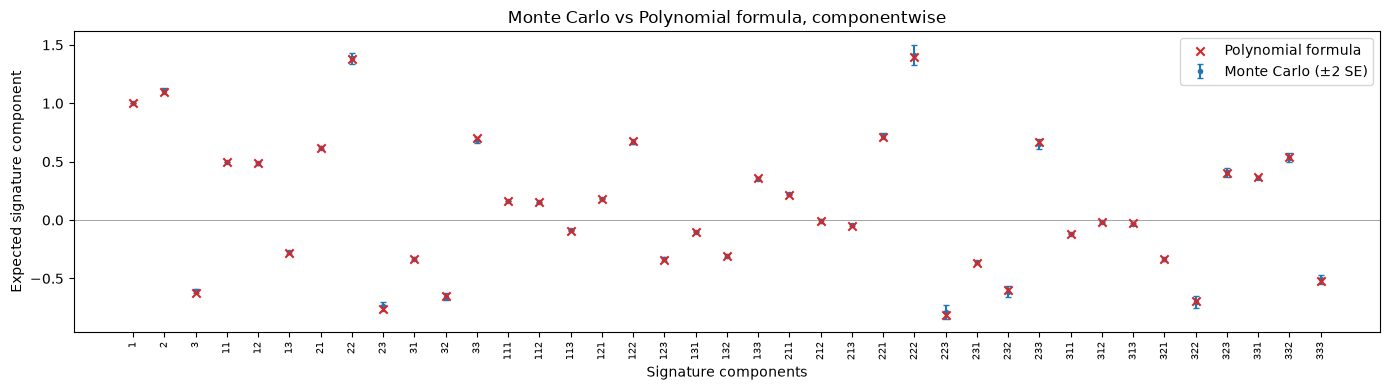

time: 271 ms (started: 2026-11-26 11:27:58 +01:00)


In [12]:
import matplotlib.pyplot as plt

# MC estimate (+/- 2 SE) vs exact formula value, one point per signature word
x = np.arange(len(table))
fig, ax = plt.subplots(figsize=(14, 4))
ax.errorbar(x, table['monte_carlo'], yerr=2 * table['std_error'],
            fmt='o', ms=3, capsize=2, color='tab:blue', label='Monte Carlo (±2 SE)')
ax.scatter(x, table['poly_formula'], marker='x', color='tab:red', zorder=3, label='Polynomial formula')
ax.set_xticks(x)
ax.set_xticklabels(table['word'], rotation=90, fontsize=7)
ax.axhline(0, color='grey', lw=0.5)
ax.set_ylabel('Expected signature component')
ax.set_xlabel('Signature components')
ax.set_title('Monte Carlo vs Polynomial formula, componentwise')
ax.legend()
plt.tight_layout()
plt.show()
